In [3]:
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt

RUTA_CSV = "../data/raw/DATASET_Denuncias_Policiales_Ene 2018 a Julio 2026.csv"

## 1. Cargar el dataset

Cada fila es: año, mes, lugar del hecho (departamento, provincia, distrito, UBIGEO), modalidad y la **cantidad** de denuncias.
Ojo: una fila **no** es una denuncia; es un conteo ya agregado por mes, distrito y modalidad.

In [4]:
df = pd.read_csv(RUTA_CSV)

print("Filas, columnas:", df.shape)
print("Valores nulos por columna:")
print(df.isna().sum())
df.head()

Filas, columnas: (369100, 8)
Valores nulos por columna:
ANIO              0
MES               0
DPTO_HECHO_NEW    0
PROV_HECHO        0
DIST_HECHO        0
UBIGEO_HECHO      0
P_MODALIDADES     0
cantidad          0
dtype: int64


,ANIO,MES,DPTO_HECHO_NEW,PROV_HECHO,DIST_HECHO,UBIGEO_HECHO,P_MODALIDADES,cantidad
0,2018,1,AMAZONAS,BAGUA,ARAMANGO,10202,Otros,4
1,2018,1,AMAZONAS,BAGUA,ARAMANGO,10202,Violencia contra la mujer e integrantes,3
2,2018,1,AMAZONAS,BAGUA,BAGUA,10201,Estafa,2
3,2018,1,AMAZONAS,BAGUA,BAGUA,10201,Hurto,25
4,2018,1,AMAZONAS,BAGUA,BAGUA,10201,Otros,52


In [5]:
# ¿Qué modalidades hay? Nos quedaremos solo con Robo y Hurto
df["P_MODALIDADES"].value_counts()

P_MODALIDADES
Otros                                      107429
Violencia contra la mujer e integrantes     94941
Hurto                                       67438
Robo                                        41751
Estafa                                      31004
Extorsión                                   19527
Secuestro                                    7010
Name: count, dtype: int64

## 2. Filtrar: Lima Metropolitana y Robo + Hurto

En este dataset el departamento de Lima está partido en dos:

* **`LIMA METROPOLITANA`** → la provincia de Lima, con sus **43 distritos** (la que usamos).
* **`REGION LIMA`** → las otras provincias (Barranca, Cañete, Huaral, …), que quedan fuera.

Por eso se filtra por `DPTO_HECHO_NEW == "LIMA METROPOLITANA"` y no por "LIMA".

In [6]:
print(df["DPTO_HECHO_NEW"].unique())

<ArrowStringArray>
[               'AMAZONAS',                  'ANCASH',
                'APURIMAC',                'AREQUIPA',
                'AYACUCHO',               'CAJAMARCA',
                   'CUSCO',            'HUANCAVELICA',
                 'HUANUCO',                     'ICA',
                   'JUNIN',             'LA LIBERTAD',
              'LAMBAYEQUE',      'LIMA METROPOLITANA',
                  'LORETO',           'MADRE DE DIOS',
                'MOQUEGUA',                   'PASCO',
                   'PIURA', 'PROV. CONST. DEL CALLAO',
                    'PUNO',             'REGION LIMA',
              'SAN MARTIN',                   'TACNA',
                  'TUMBES',                 'UCAYALI']
Length: 26, dtype: str


In [7]:
lima = df[
    (df["DPTO_HECHO_NEW"] == "LIMA METROPOLITANA")
    & (df["P_MODALIDADES"].isin(["Robo", "Hurto"]))
].copy()

print("Filas después del filtro:", len(lima))
print("Distritos (UBIGEO distintos):", lima["UBIGEO_HECHO"].nunique())
print("Total de denuncias Robo + Hurto:", f"{lima['cantidad'].sum():,}".replace(",", " "))

Filas después del filtro: 8518
Distritos (UBIGEO distintos): 43
Total de denuncias Robo + Hurto: 940 555


In [8]:
# Revisión de calidad: cada UBIGEO debe tener un solo nombre de distrito,
# y no debe haber filas repetidas para el mismo distrito, mes y modalidad
print("Nombres por UBIGEO (debe ser 1):", lima.groupby("UBIGEO_HECHO")["DIST_HECHO"].nunique().max())
print("Filas duplicadas:", lima.duplicated(["UBIGEO_HECHO", "ANIO", "MES", "P_MODALIDADES"]).sum())
print("Cantidades negativas o cero:", (lima["cantidad"] <= 0).sum())

Nombres por UBIGEO (debe ser 1): 1
Filas duplicadas: 0
Cantidades negativas o cero: 0


## 3. Agrupar por distrito y mes

Dejamos **una fila por distrito y mes**, con robo y hurto en columnas separadas y su suma en `TOTAL`.
`TOTAL` es lo que va a predecir la MLP; `ROBO` y `HURTO` se guardan por si sirven después.

In [9]:
tabla = lima.pivot_table(
    index=["UBIGEO_HECHO", "DIST_HECHO", "ANIO", "MES"],
    columns="P_MODALIDADES",
    values="cantidad",
    aggfunc="sum",
    fill_value=0,
).reset_index()

tabla.columns.name = None
tabla = tabla.rename(columns={"Robo": "ROBO", "Hurto": "HURTO"})
tabla["TOTAL"] = tabla["ROBO"] + tabla["HURTO"]

print("Filas:", len(tabla), "| Lo esperado: 43 × 103 =", 43 * 103)
tabla.head()

Filas: 4360 | Lo esperado: 43 × 103 = 4429


,UBIGEO_HECHO,DIST_HECHO,ANIO,MES,HURTO,ROBO,TOTAL
0,150101,LIMA,2018,1,557,323,880
1,150101,LIMA,2018,2,633,381,1014
2,150101,LIMA,2018,3,639,360,999
3,150101,LIMA,2018,4,635,367,1002
4,150101,LIMA,2018,5,624,481,1105


## 4. Completar los meses que faltan con 0

Salen menos de 4 429 filas porque, si un distrito no tuvo ninguna denuncia de robo ni hurto en un mes,
ese mes **no aparece** en el CSV. Para la predicción cada distrito necesita sus **103 meses seguidos**
(si falta uno, los meses anteriores t−1, t−2 y t−11 quedan mal alineados), así que creamos la grilla completa
distrito × mes y rellenamos con 0 lo que falta.

In [10]:
# Lista de los 43 distritos (UBIGEO + nombre)
distritos = tabla[["UBIGEO_HECHO", "DIST_HECHO"]].drop_duplicates()

# Los 103 meses: enero 2018 a julio 2026
meses = pd.DataFrame({"FECHA": pd.date_range("2018-01-01", "2026-07-01", freq="MS")})
meses["ANIO"] = meses["FECHA"].dt.year
meses["MES"] = meses["FECHA"].dt.month

# Grilla completa: cada distrito con cada mes (producto cruzado)
grilla = distritos.merge(meses, how="cross")

datos = grilla.merge(tabla, on=["UBIGEO_HECHO", "DIST_HECHO", "ANIO", "MES"], how="left")
faltantes = datos["TOTAL"].isna().sum()
datos[["ROBO", "HURTO", "TOTAL"]] = datos[["ROBO", "HURTO", "TOTAL"]].fillna(0).astype(int)

print("Meses agregados con 0:", faltantes)
print("Filas ahora:", len(datos))

Meses agregados con 0: 69
Filas ahora: 4429


In [11]:
# ¿En qué distritos estaban esos meses vacíos? (suelen ser los distritos pequeños de playa)
(datos[datos["TOTAL"] == 0]
 .groupby("DIST_HECHO").size()
 .sort_values(ascending=False)
 .rename("meses_en_0"))

DIST_HECHO
SANTA MARIA DEL MAR    50
PUNTA NEGRA             9
SAN BARTOLO             5
PUCUSANA                3
PUNTA HERMOSA           2
Name: meses_en_0, dtype: int64

## 5. Columnas extra

* **`UBIGEO`**: el código como texto de 6 dígitos (`150101` … `150143`). Es la llave que une todo.
* **`DIST_NORM`**: nombre sin tildes y en mayúsculas (`BREÑA` → `BRENA`), para cruzar con OpenStreetMap.
* **`CUARENTENA_2020`**: 1 en los meses de 2020, porque la cuarentena bajó las denuncias de forma anormal.
* **`CONJUNTO`**: división **temporal** (nunca al azar): entrenamiento 2018–2024, validación 2025, prueba ene–jul 2026.

In [12]:
def normalizar(nombre):
    # Quita tildes y la Ñ (NFKD separa la letra de su acento) y deja todo en mayúsculas
    sin_tildes = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode("ascii")
    return sin_tildes.upper().strip()

datos["UBIGEO"] = datos["UBIGEO_HECHO"].astype(str).str.zfill(6)
datos["DIST_NORM"] = datos["DIST_HECHO"].apply(normalizar)
datos["CUARENTENA_2020"] = (datos["ANIO"] == 2020).astype(int)

def conjunto(anio):
    if anio <= 2024:
        return "entrenamiento"
    if anio == 2025:
        return "validacion"
    return "prueba"

datos["CONJUNTO"] = datos["ANIO"].apply(conjunto)

# Orden final de columnas
datos = datos[["UBIGEO", "DIST_HECHO", "DIST_NORM", "FECHA", "ANIO", "MES",
               "ROBO", "HURTO", "TOTAL", "CUARENTENA_2020", "CONJUNTO"]]
datos = datos.sort_values(["UBIGEO", "FECHA"]).reset_index(drop=True)
datos.head()

,UBIGEO,DIST_HECHO,DIST_NORM,FECHA,ANIO,MES,ROBO,HURTO,TOTAL,CUARENTENA_2020,CONJUNTO
0,150101,LIMA,LIMA,2018-01-01,2018,1,323,557,880,0,entrenamiento
1,150101,LIMA,LIMA,2018-02-01,2018,2,381,633,1014,0,entrenamiento
2,150101,LIMA,LIMA,2018-03-01,2018,3,360,639,999,0,entrenamiento
3,150101,LIMA,LIMA,2018-04-01,2018,4,367,635,1002,0,entrenamiento
4,150101,LIMA,LIMA,2018-05-01,2018,5,481,624,1105,0,entrenamiento


In [13]:
# Nombres que cambiaron al normalizar
datos.loc[datos["DIST_HECHO"] != datos["DIST_NORM"], ["DIST_HECHO", "DIST_NORM"]].drop_duplicates()

,DIST_HECHO,DIST_NORM
412,BREÑA,BRENA


## 6. Validaciones

Si alguna de estas líneas falla, el notebook se detiene y avisa: así sabemos que la tabla está bien antes de pasarla.

In [14]:
assert len(datos) == 43 * 103, "No hay 4 429 filas"
assert datos["UBIGEO"].nunique() == 43, "No hay 43 distritos"
assert datos.groupby("UBIGEO")["FECHA"].nunique().eq(103).all(), "Algún distrito no tiene 103 meses"
assert not datos.duplicated(["UBIGEO", "FECHA"]).any(), "Hay filas repetidas"
assert datos["TOTAL"].sum() == lima["cantidad"].sum(), "Se perdieron o duplicaron denuncias"
assert (datos["TOTAL"] == datos["ROBO"] + datos["HURTO"]).all()
assert datos["UBIGEO"].str.match(r"^1501\d{2}$").all(), "Hay un UBIGEO fuera de la provincia de Lima"

print("Todas las validaciones pasaron ✔")
print(datos["CONJUNTO"].value_counts())

Todas las validaciones pasaron ✔
CONJUNTO
entrenamiento    3612
validacion        516
prueba            301
Name: count, dtype: int64


## 7. Exploración rápida (cifras para la Introducción)

In [15]:
total = datos["TOTAL"].sum()
por_distrito = datos.groupby("DIST_HECHO")["TOTAL"].sum().sort_values(ascending=False)
top10 = por_distrito.head(10)

print(f"Total Robo + Hurto en Lima (ene 2018 – jul 2026): {total:,}".replace(",", " "))
print(f"Los 10 distritos con más denuncias concentran el {top10.sum() / total:.1%}".replace(".", ","))
print()
print((top10 / total * 100).round(1).rename("% del total").to_string())

Total Robo + Hurto en Lima (ene 2018 – jul 2026): 940 555
Los 10 distritos con más denuncias concentran el 56,8%

DIST_HECHO
LIMA                       10.5
SAN JUAN DE LURIGANCHO      9.3
SAN MARTIN DE PORRES        5.6
SANTIAGO DE SURCO           5.1
COMAS                       4.9
LOS OLIVOS                  4.8
ATE                         4.5
VILLA MARIA DEL TRIUNFO     4.3
LA VICTORIA                 4.3
INDEPENDENCIA               3.6


In [16]:
# Denuncias por año (2026 solo tiene enero a julio)
datos.groupby("ANIO")[["ROBO", "HURTO", "TOTAL"]].sum()

,ROBO,HURTO,TOTAL
ANIO,,,
2018,50052,69339,119391
2019,46470,63620,110090
2020,21783,39056,60839
2021,27352,49583,76935
2022,38112,60718,98830
2023,71767,91953,163720
2024,52354,93690,146044
2025,28190,78044,106234
2026,14569,43903,58472


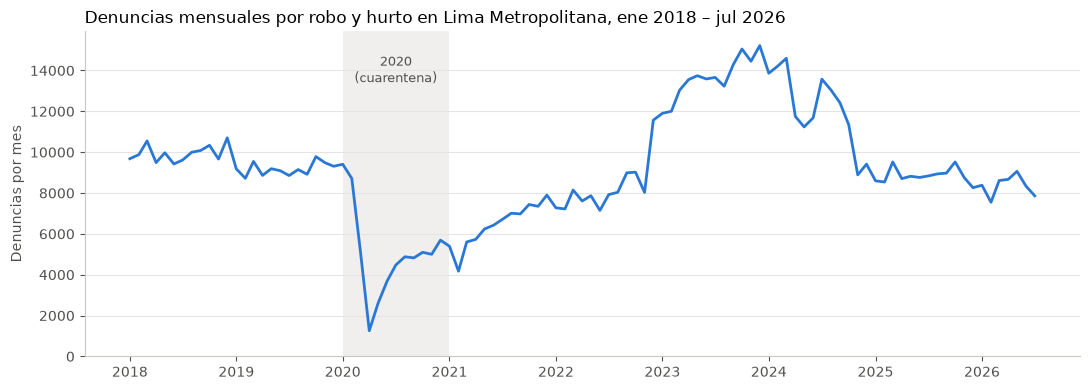

In [17]:
AZUL = "#2a78d6"
TINTA = "#52514e"

def estilo(ax):
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    for lado in ["left", "bottom"]:
        ax.spines[lado].set_color("#c9c8c3")
    ax.tick_params(colors=TINTA)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)

mensual = datos.groupby("FECHA")["TOTAL"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(mensual.index, mensual.values, color=AZUL, linewidth=2)
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color="#e6e5e1", alpha=0.6, linewidth=0)
ax.text(pd.Timestamp("2020-07-01"), mensual.max() * 0.97, "2020\n(cuarentena)", ha="center", va="top", color=TINTA, fontsize=9)
ax.set_title("Denuncias mensuales por robo y hurto en Lima Metropolitana, ene 2018 – jul 2026", loc="left", fontsize=12)
ax.set_ylabel("Denuncias por mes", color=TINTA)
ax.set_ylim(bottom=0)
estilo(ax)
plt.tight_layout()
plt.show()

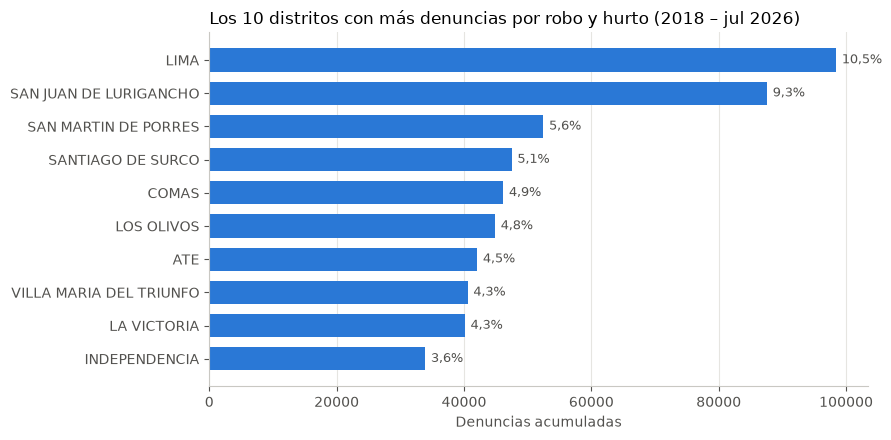

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
orden = top10.sort_values()
barras = ax.barh(orden.index, orden.values, color=AZUL, height=0.7)
ax.bar_label(barras, labels=[f"{v / total:.1%}".replace(".", ",") for v in orden.values],
             padding=4, color=TINTA, fontsize=9)
ax.set_title("Los 10 distritos con más denuncias por robo y hurto (2018 – jul 2026)", loc="left", fontsize=12)
ax.set_xlabel("Denuncias acumuladas", color=TINTA)
estilo(ax)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#e6e5e1", linewidth=0.8)
plt.tight_layout()
plt.show()

## 8. Tabla del UBIGEO

El UBIGEO tiene 6 dígitos: **2 de departamento + 2 de provincia + 2 de distrito**.
En la provincia de Lima todos empiezan con `1501` (15 = Lima, 01 = provincia de Lima) y los dos últimos van de `01` a `43`.
Esta tabla es la que va en el informe y la que usan Hugo (OSM, por `DIST_NORM`) y Deivis (RENAMU, directo por `UBIGEO`).

In [19]:
ubigeo = (datos[["UBIGEO", "DIST_HECHO", "DIST_NORM"]]
          .drop_duplicates()
          .sort_values("UBIGEO")
          .reset_index(drop=True))
ubigeo["DEPARTAMENTO"] = ubigeo["UBIGEO"].str[:2]
ubigeo["PROVINCIA"] = ubigeo["UBIGEO"].str[2:4]
ubigeo["DISTRITO"] = ubigeo["UBIGEO"].str[4:6]
ubigeo

,UBIGEO,DIST_HECHO,DIST_NORM,DEPARTAMENTO,PROVINCIA,DISTRITO
0,150101,LIMA,LIMA,15,01,01
1,150102,ANCON,ANCON,15,01,02
2,150103,ATE,ATE,15,01,03
3,150104,BARRANCO,BARRANCO,15,01,04
4,150105,BREÑA,BRENA,15,01,05
5,150106,CARABAYLLO,CARABAYLLO,15,01,06
6,150107,CHACLACAYO,CHACLACAYO,15,01,07
7,150108,CHORRILLOS,CHORRILLOS,15,01,08
8,150109,CIENEGUILLA,CIENEGUILLA,15,01,09
9,150110,COMAS,COMAS,15,01,10


## 9. Guardar

In [20]:
datos.to_csv("../data/processed/lima_robo_hurto_mensual.csv", index=False, date_format="%Y-%m-%d")
ubigeo.to_csv("../data/processed/ubigeo_lima.csv", index=False)

print("Guardado: lima_robo_hurto_mensual.csv", datos.shape)
print("Guardado: ubigeo_lima.csv", ubigeo.shape)

Guardado: lima_robo_hurto_mensual.csv (4429, 11)
Guardado: ubigeo_lima.csv (43, 6)
